In [1]:
import pandas as pd

orders = pd.read_csv("olist_orders_dataset.csv", parse_dates=[
    "order_purchase_timestamp", "order_delivered_customer_date",
    "order_estimated_delivery_date"])
items = pd.read_csv("olist_order_items_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
reviews = pd.read_csv("olist_order_reviews_dataset.csv")

for name, df in [("orders", orders), ("items", items),
                 ("customers", customers), ("reviews", reviews)]:
    print(name, df.shape)
    print(df.isna().sum()[df.isna().sum() > 0], "\n")

orders (99441, 8)
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64 

items (112650, 7)
Series([], dtype: int64) 

customers (99441, 5)
Series([], dtype: int64) 

reviews (99224, 7)
review_comment_title      87656
review_comment_message    58247
dtype: int64 



In [2]:
# Keep only delivered orders that have a delivery date
delivered = orders[(orders["order_status"] == "delivered") &
                   orders["order_delivered_customer_date"].notna()].copy()

# Delay in days: positive means the order arrived after the promised date
delivered["delay_days"] = (delivered["order_delivered_customer_date"]
                           - delivered["order_estimated_delivery_date"]).dt.days
delivered["is_late"] = delivered["delay_days"] > 0

# Some orders have several reviews, so keep the latest one per order
reviews_clean = (reviews.sort_values("review_creation_date")
                 .drop_duplicates("order_id", keep="last")
                 [["order_id", "review_score"]])

df = delivered.merge(reviews_clean, on="order_id", how="inner")

print(df.shape)
print(df["is_late"].value_counts(normalize=True).round(3))
print(df.groupby("is_late")["review_score"].agg(["mean", "count"]).round(2))

(95824, 11)
is_late
False    0.933
True     0.067
Name: proportion, dtype: float64
         mean  count
is_late             
False    4.29  89443
True     2.27   6381


                mean  count
delay_bucket               
On time         4.29  89443
1-3 days late   3.29   1852
4-7 days late   2.10   1748
8-14 days late  1.67   1446
15+ days late   1.72   1335 

is_late
False    0.066
True     0.538
Name: review_score, dtype: float64 

Revenue on late orders: 953367 out of 13108744


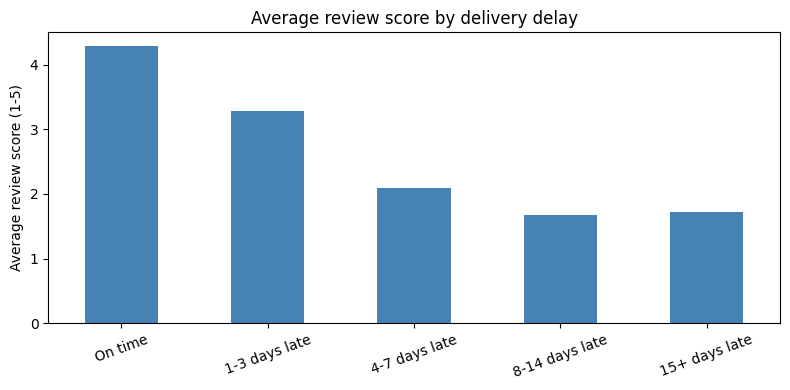

In [3]:
import matplotlib.pyplot as plt

# 1) Review score by how late the order was
bins = [-999, 0, 3, 7, 14, 999]
labels = ["On time", "1-3 days late", "4-7 days late",
          "8-14 days late", "15+ days late"]
df["delay_bucket"] = pd.cut(df["delay_days"], bins=bins, labels=labels)
bucket = df.groupby("delay_bucket", observed=True)["review_score"].agg(["mean", "count"]).round(2)
print(bucket, "\n")

# 2) Share of 1-star reviews: late vs on time
print((df["review_score"] == 1).groupby(df["is_late"]).mean().round(3), "\n")

# 3) Revenue tied to late orders
order_value = items.groupby("order_id")["price"].sum().rename("order_value")
df = df.merge(order_value, on="order_id", how="left")
late_rev = df.loc[df["is_late"], "order_value"].sum()
print("Revenue on late orders:", round(late_rev), "out of", round(df["order_value"].sum()))

# Chart
ax = bucket["mean"].plot(kind="bar", figsize=(8, 4), color="steelblue")
ax.set_title("Average review score by delivery delay")
ax.set_ylabel("Average review score (1-5)")
ax.set_xlabel("")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

                orders  late_rate  avg_score
customer_state                              
MA                 712      0.171      3.833
CE                1273      0.137      3.944
RJ               12211      0.119      3.966
BA                3229      0.119      3.930
PA                 933      0.107      3.914
ES                1969      0.104      4.079
PB                 512      0.102      4.076
MS                 699      0.097      4.162
PE                1579      0.094      4.084
SC                3519      0.081      4.134


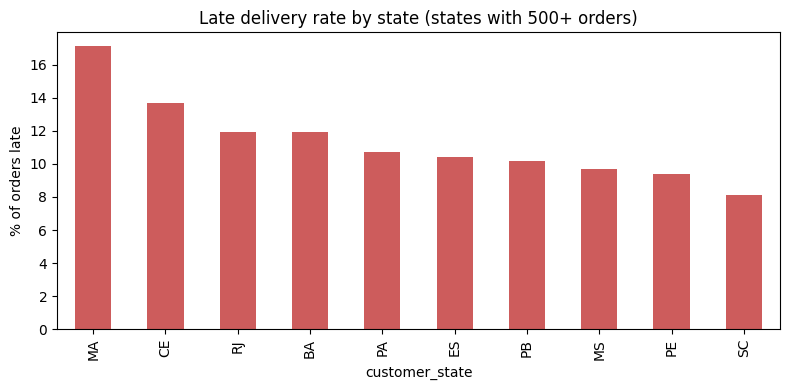

In [4]:
df = df.merge(customers[["customer_id", "customer_state"]],
              on="customer_id", how="left")

state = (df.groupby("customer_state")
         .agg(orders=("order_id", "count"),
              late_rate=("is_late", "mean"),
              avg_score=("review_score", "mean"))
         .query("orders >= 500")
         .sort_values("late_rate", ascending=False)
         .round(3))
print(state.head(10))

ax = state["late_rate"].head(10).mul(100).plot(kind="bar", figsize=(8, 4), color="indianred")
ax.set_title("Late delivery rate by state (states with 500+ orders)")
ax.set_ylabel("% of orders late")
plt.tight_layout()
plt.show()

         orders    revenue  late_rate
month                                
2017-01     741  110660.00      0.028
2017-02    1643  233035.02      0.026
2017-03    2527  353291.42      0.045
2017-04    2290  338491.56      0.064
2017-05    3517  484800.20      0.028
2017-06    3111  419278.13      0.030
2017-07    3842  477022.56      0.027
2017-08    4165  548476.37      0.029
2017-09    4118  603608.68      0.043
2017-10    4446  641918.45      0.040
2017-11    7237  978646.18      0.123
2017-12    5461  715880.10      0.073
2018-01    7013  915586.88      0.056
2018-02    6507  820193.91      0.140
2018-03    6948  943358.51      0.187
2018-04    6752  968034.66      0.044
2018-05    6722  972258.23      0.065
2018-06    6072  853592.86      0.012
2018-07    6118  855564.35      0.033
2018-08    6330  835272.25      0.061 

Customers: 92747
Repeat customer rate: 3.0 %


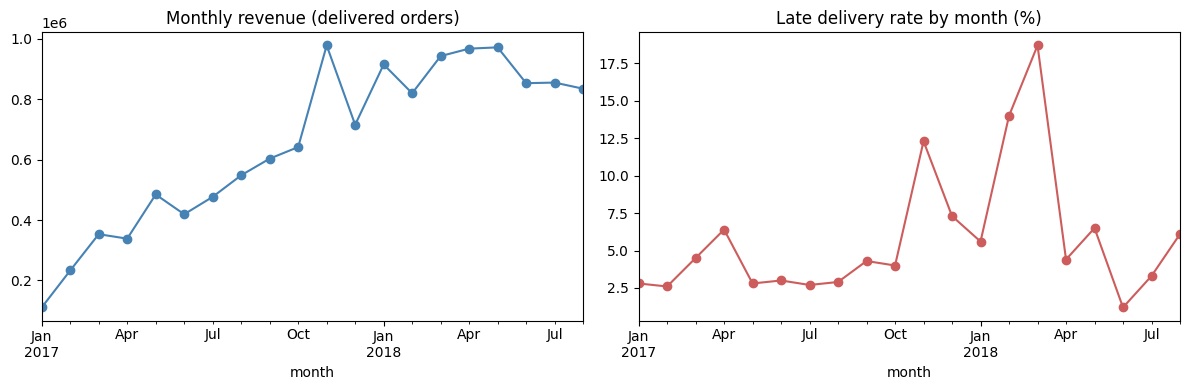

In [5]:
# Monthly orders, revenue and late rate
df["month"] = df["order_purchase_timestamp"].dt.to_period("M")
monthly = (df.groupby("month")
           .agg(orders=("order_id", "count"),
                revenue=("order_value", "sum"),
                late_rate=("is_late", "mean"))
           .round(3))
monthly = monthly[monthly["orders"] >= 300]   # drop tiny edge months
print(monthly, "\n")

# Repeat customers
df = df.merge(customers[["customer_id", "customer_unique_id"]],
              on="customer_id", how="left")
per_customer = df.groupby("customer_unique_id")["order_id"].nunique()
print("Customers:", len(per_customer))
print("Repeat customer rate:", round((per_customer > 1).mean() * 100, 1), "%")

# Charts
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
monthly["revenue"].plot(ax=ax[0], marker="o", color="steelblue")
ax[0].set_title("Monthly revenue (delivered orders)")
monthly["late_rate"].mul(100).plot(ax=ax[1], marker="o", color="indianred")
ax[1].set_title("Late delivery rate by month (%)")
plt.tight_layout()
plt.show()

In [6]:
# Do customers whose FIRST order was late come back less often?
first = (df.sort_values("order_purchase_timestamp")
           .groupby("customer_unique_id")
           .first()[["is_late", "review_score"]])
orders_per = df.groupby("customer_unique_id")["order_id"].nunique()
first["repeat"] = orders_per.reindex(first.index) > 1
print(first.groupby("is_late")["repeat"].agg(["mean", "count"]).round(4))

# Save a clean file for the dashboard
export = df[["order_id", "customer_unique_id", "customer_state",
             "order_purchase_timestamp", "delay_days", "is_late",
             "delay_bucket", "review_score", "order_value"]]
export.to_csv("olist_clean.csv", index=False)
from google.colab import files
files.download("olist_clean.csv")

           mean  count
is_late               
False    0.0301  86533
True     0.0256   6214


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>